# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [11]:
import numpy as np
from matplotlib import pyplot as plt

In [10]:
#Read in data set
from scipy.io import readsav
filepathlaptop = '/home/vesna/5tes/Numerische_methoden/übungen/exercise 2/galahamr.sav'  #change this to the path on your computer where the file is stored
filepathdesktop = '/home/av/uni stuff/Num_meth/übungen/Ü2/galahamr.sav'  #change this to the path on your computer where the file is stored
stars = readsav(filepathdesktop)  #change this to the path on your computer where the file is stored

In [2]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

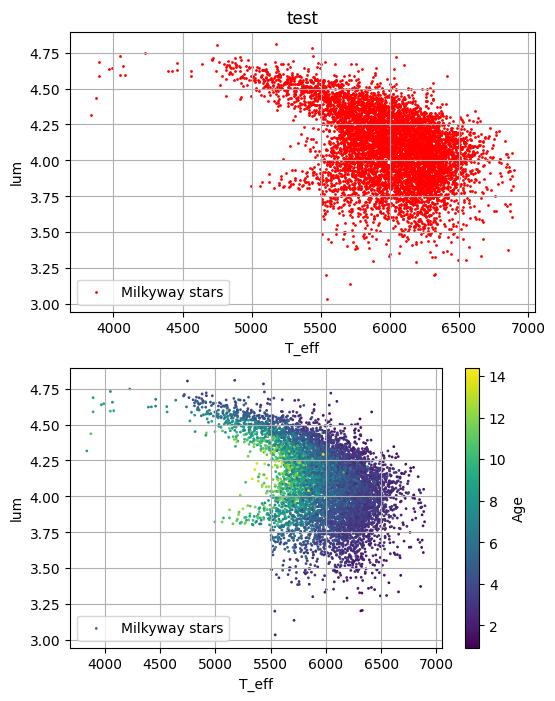

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Generate some dataset
x = teff
y = logg


# The most simple plot with ax. syntax
fig, axs = plt.subplots(2, 1, figsize=(6, 8))
axs[0].scatter(x, y, color='r', label='Milkyway stars', s=1)
axs[0].set_title('test')
axs[0].set_xlabel('T_eff')
axs[0].set_ylabel('lum')
axs[0].legend()
axs[0].grid(True)

sc = axs[1].scatter(x, y, c=age, label='Milkyway stars', s=1)
axs[1].set_xlabel('T_eff')
axs[1].set_ylabel('lum')
axs[1].legend()
axs[1].grid(True)
cbar=fig.colorbar(sc, ax=axs[1])
cbar.set_label("Age")
plt.show()

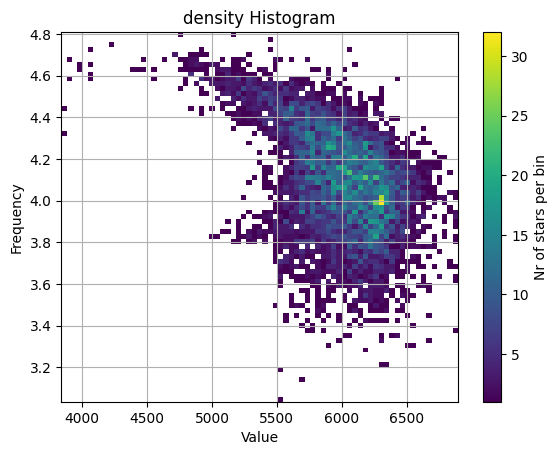

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# A simple histogram Plot
sc = plt.hist2d(x, y, bins=75, cmin= 1)
plt.title('density Histogram')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.grid(True)
cbar = plt.colorbar()
cbar.set_label("Nr of stars per bin")
plt.show()


### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

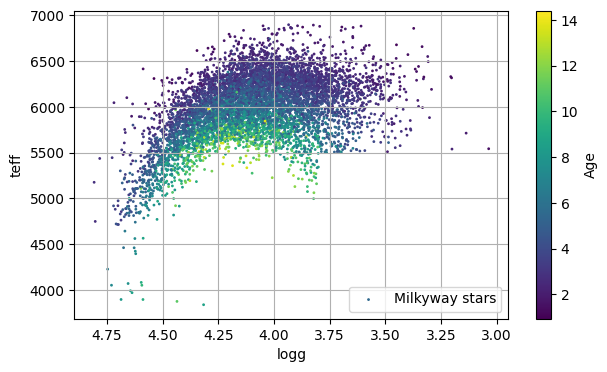

In [5]:
import matplotlib.pyplot as plt

y = teff
x = logg

fig, ax = plt.subplots(1, 1, figsize=(7, 4))

sc = ax.scatter(x, y, c=age, label='Milkyway stars', s=1)
ax.set_ylabel('teff')
ax.set_xlabel('logg')
ax.legend()
ax.grid()
cbar=fig.colorbar(sc)
cbar.set_label("Age")
plt.gca().invert_xaxis()
plt.show()

logg(teff) = -0.0003286 * teff + 6.06


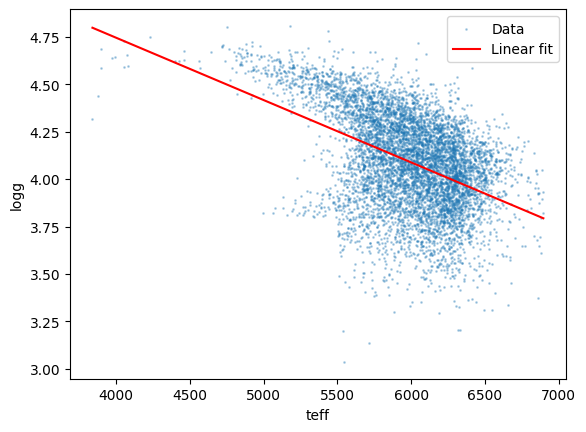

In [6]:
import numpy as np
import scipy as scipy
#print(np.mean(teff))
#logg(teff) = m *teff + b

m, b = np.polyfit(teff, logg, 1)
logg_fit = lambda t: m * t + b

print(f"logg(teff) = {m:.4g} * teff + {b:.4g}")

order = np.argsort(teff)
plt.scatter(teff, logg, s=1, alpha=0.3, label="Data")
plt.plot(teff[order], logg_fit(teff[order]), color="red", label="Linear fit")
plt.xlabel("teff")
plt.ylabel("logg")
plt.legend()
plt.show()

[5542.103                nan           nan           nan 5712.6758
           nan 5538.4307     6323.18015              nan           nan
 6190.8745     6308.33866667 6320.02415    6267.19611667 6052.967275
 6051.35274    6101.19124167 6032.387775   6132.16686875 6027.58303889
 6130.50459583 6190.359012   6191.4361037  6175.72824    6069.69584286
 6103.26622041 6092.0768431  6114.15570278 6047.66346364 6100.75129355
 6088.64006737 6122.64165254 6034.08288212 6068.18911916 6055.49441732
 6080.76229778 6068.94335622 6123.90512066 6086.71881611 6084.7936917
 6135.83305434 6137.6806682  6135.08750575 6088.62890154 6100.51087063
 6066.44121224 6123.71299538 6066.79704769 6061.13263023 6048.62801273
 5999.70862927 5982.65725865 6000.60593033 5943.63419943 5882.27795691
 5839.69611938 5814.57898639 5747.28865956 5742.64595161 5649.98738594
 5642.47829802 5543.84419512 5480.83760864 5427.35234286 5351.24773538
 5200.37037647 5125.32331739 5081.43975667 4963.89398571 5077.88656
 4881.9190625  5

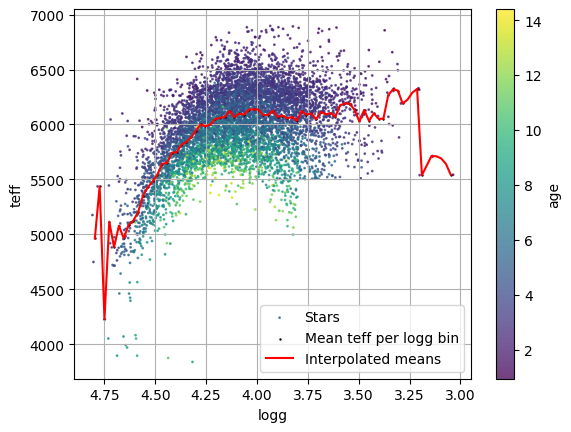

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic
from scipy.interpolate import PchipInterpolator

# Keep valid paired values
teff_arr = np.asarray(teff)
logg_arr = np.asarray(logg)
valid = np.isfinite(teff_arr) & np.isfinite(logg_arr)

# Mean teff in each logg bin
mean_teff, edges, _ = binned_statistic(
    logg_arr[valid], teff_arr[valid], statistic="mean", bins=75
)
logg_centers = (edges[:-1] + edges[1:]) / 2

print(mean_teff)

# Drop empty bins
ok = np.isfinite(mean_teff)
x = logg_centers[ok]
y = mean_teff[ok]



# A function passing through the binned means
teff_from_logg = PchipInterpolator(x, y)

# Plot the data, binned means, and interpolated curve
logg_plot = np.linspace(x.min(), x.max(), 75)
sc = plt.scatter(logg_arr[valid], teff_arr[valid], s=1, alpha=0.75, label="Stars", c=age)
plt.scatter(x, y, color="black", label="Mean teff per logg bin", s=0.5)
plt.plot(logg_plot, teff_from_logg(logg_plot), color="red", label="Interpolated means")
plt.xlabel("logg")
plt.ylabel("teff")
plt.legend()
cbar = plt.colorbar(sc)
cbar.set_label("age")
plt.gca().invert_xaxis()
plt.grid()
plt.show()

### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

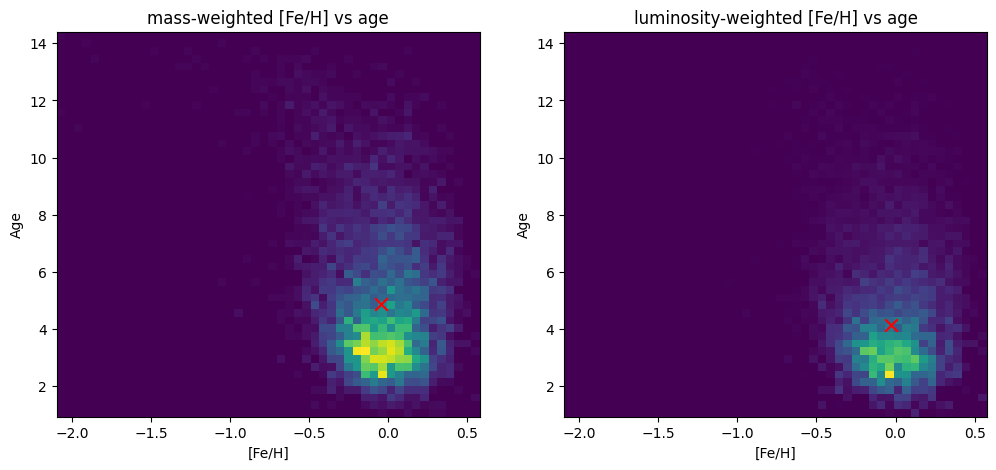

In [22]:
import numpy as np
import matplotlib.pyplot as plt

valid = np.isfinite(feh) & np.isfinite(age) & np.isfinite(mass)

x = feh[valid]
y = age[valid]
w_mass = mass[valid]
w_lum = mass[valid]**4

# mass-weighted density
H_mass, xedges, yedges = np.histogram2d(x, y, bins=50, weights=w_mass)

# luminosity-weighted density
H_lum, _, _ = np.histogram2d(x, y, bins=50, weights=w_lum)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].pcolormesh(xedges, yedges, H_mass.T, shading='auto')
axes[0].scatter(np.average(x, weights=w_mass), np.average(y, weights=w_mass),
                color='red', marker='x', s=80)
axes[0].set_title("mass-weighted [Fe/H] vs age")
axes[0].set_xlabel("[Fe/H]")
axes[0].set_ylabel("Age")

im2 = axes[1].pcolormesh(xedges, yedges, H_lum.T, shading='auto')
axes[1].scatter(np.average(x, weights=w_lum), np.average(y, weights=w_lum),
                color='red', marker='x', s=80)
axes[1].set_title("luminosity-weighted [Fe/H] vs age")
axes[1].set_xlabel("[Fe/H]")
axes[1].set_ylabel("Age")

plt.show()